# Time series II

The following tutorial contains Python examples for solving time series forecasting problems. You should refer to the Slides Week 9 to understand some of the concepts introduced in this tutorial.

The tutorial covers:
1. Box-Cox transformation to stabilise variance.
2. ACF and PACF to choose model orders.
3. ARIMA and seasonal ARIMA models.
4. Model performance comparison with RMSE.

#### Toolbox
1. KPSS test: `from statsmodels.tsa.stattools import kpss`  
   https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html
2. Box-Cox transformation: `from scipy.stats import boxcox`  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.boxcox.html
3. ACF and PACF: `from statsmodels.graphics.tsaplots import plot_acf, plot_pacf`  
   https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html  
   https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html
4. ARIMA: `from statsmodels.tsa.arima.model import ARIMA`  
   https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html#statsmodels.tsa.arima.model.ARIMA

The notebook follows two sections:
- **1: Data preparation** – load, check stationarity, transform, split train/test.
- **2: Choose, train and evaluate models** – for each model: choose orders, train, plot forecast vs actuals, compute RMSE. We use 4 models:
   - Model 1: ARMA(2,1)
   - Model 2: ARIMA(2,1,1)
   - Model 3: Seasonal ARIMA
   - Model 4: ETS / Holt-Winters


##  Setup: import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import root_mean_squared_error
from scipy.stats import boxcox
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from matplotlib import pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

# 1: Data Preparation

## 1.1 Load and plot the raw monthly heater demand

`year_month` is read as text, which matplotlib would treat as 198 separate categories and the x-axis labels would overlap. Convert it to datetime so every plot below gets a proper date axis.

In [2]:
heater = pd.read_csv('heater.csv')
heater.head()

,year_month,demand
0,2004-01,27
1,2004-02,18
2,2004-03,14
3,2004-04,13
4,2004-05,13


In [3]:
heater['year_month'] = pd.to_datetime(heater['year_month'], format = '%Y-%m')

In [4]:
heater.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year_month  198 non-null    datetime64[ns]
 1   demand      198 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 3.2 KB


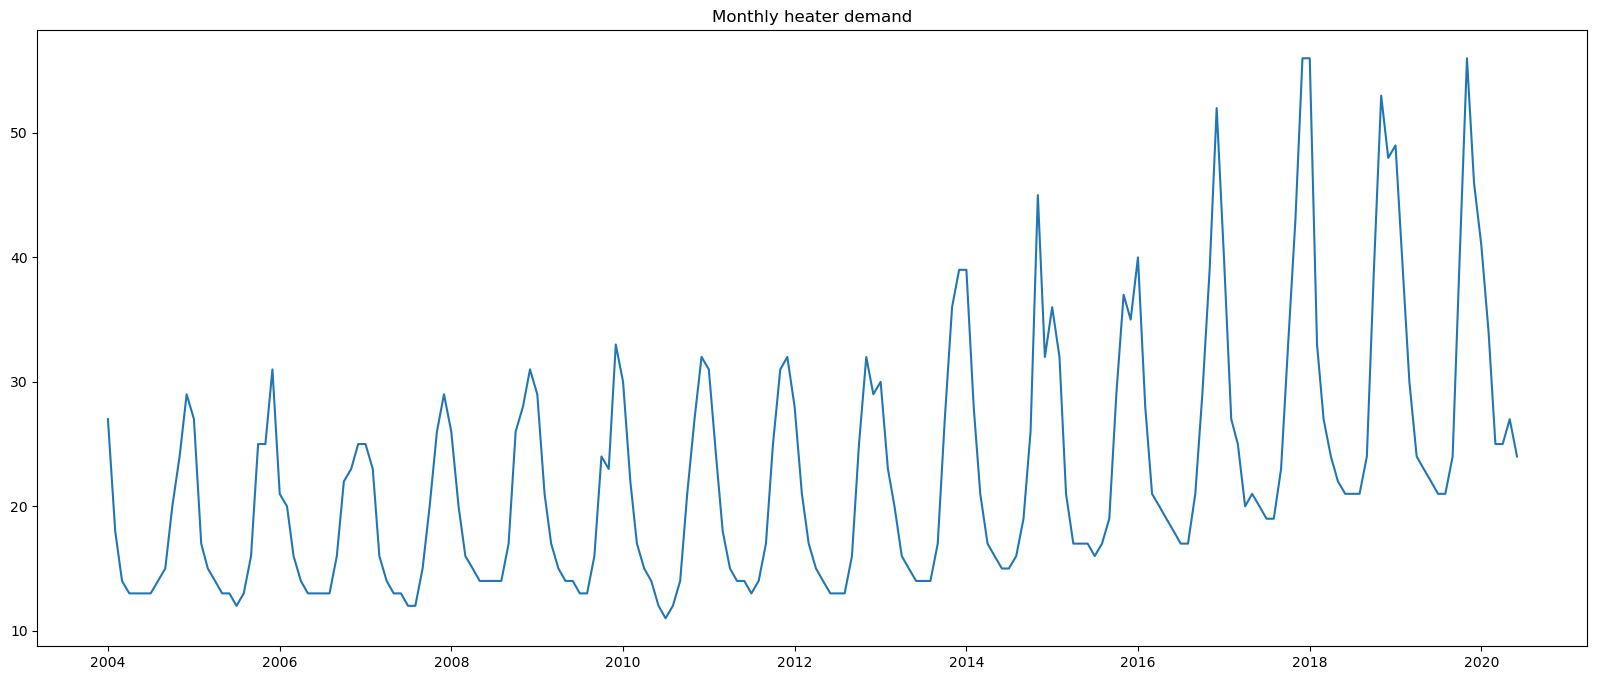

In [5]:
plt.figure(figsize = (20,8))
plt.plot(heater['year_month'], heater['demand'])
plt.title('Monthly heater demand')
plt.show()

## 1.2 Stationarity check: Is the time series stationary?

No. The data has an increasing trend and variance, and seasonal patterns. Let's confirm with the KPSS test.

In [6]:
kpss_stat, pval, lags, crit = kpss(heater['demand'], regression = 'c', nlags = 'auto')
print('p Value to the KPSS test is: ',pval)

p Value to the KPSS test is:  0.01


Because p-value is below 0.05, we consider the time series as non-stationary at a confidence level of 95%.

## 1.3 Data transformation to achieve stationarity

### 1.3.1 (a) Apply Box-Cox to stabilise the variance

In [7]:
#if parameter lmbda is none, the model will find the optimal parameter
BCheater, lmbda = boxcox(heater['demand']) 
print(BCheater[:10])
print(lmbda)

[1.33645184 1.28437996 1.24430885 1.23115732 1.23115732 1.23115732
 1.23115732 1.24430885 1.25598394 1.29928758]
-0.6645210424882915


#### Plot the Box-Cox transformed series

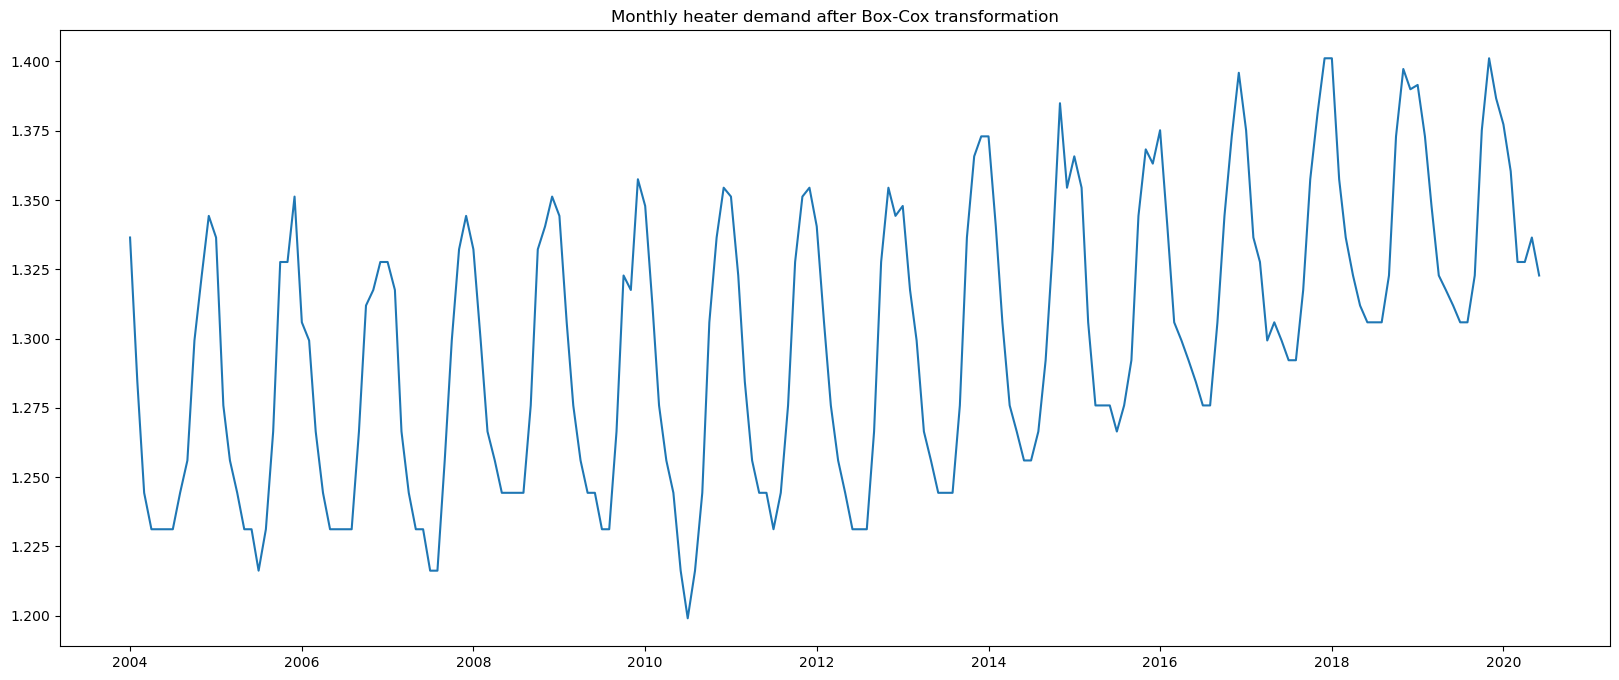

In [8]:
heater['demand_BC'] = BCheater
plt.figure(figsize = (20,8))
plt.plot(heater['year_month'], heater['demand_BC'])
plt.title('Monthly heater demand after Box-Cox transformation')
plt.show()

The issue of increasing variance is alleviated. The time series data still exhibits an increasing trend and seasonality.

### 1.3.2 (b) Subtract the monthly average to de-seasonalise

In [9]:
heater['month'] = heater['year_month'].dt.month
print(heater.head())

  year_month  demand  demand_BC  month
0 2004-01-01      27   1.336452      1
1 2004-02-01      18   1.284380      2
2 2004-03-01      14   1.244309      3
3 2004-04-01      13   1.231157      4
4 2004-05-01      13   1.231157      5


#### Compute the average Box-Cox demand for each month

In [10]:
heater_by_month = heater.groupby('month')['demand_BC'].mean().reset_index()
print(heater_by_month.head(12))

    month  demand_BC
0       1   1.354655
1       2   1.323694
2       3   1.292226
3       4   1.272577
4       5   1.265195
5       6   1.259130
6       7   1.248622
7       8   1.253516
8       9   1.281419
9      10   1.332302
10     11   1.354482
11     12   1.362085


In [11]:
heater_by_month = heater_by_month.rename(columns = {'demand_BC':'demand_month_avg'})
print(heater_by_month.head(12))

    month  demand_month_avg
0       1          1.354655
1       2          1.323694
2       3          1.292226
3       4          1.272577
4       5          1.265195
5       6          1.259130
6       7          1.248622
7       8          1.253516
8       9          1.281419
9      10          1.332302
10     11          1.354482
11     12          1.362085


#### Merge the monthly averages back into the main table

In [12]:
heater = heater.merge(heater_by_month, on = 'month')
print(heater.head())

  year_month  demand  demand_BC  month  demand_month_avg
0 2004-01-01      27   1.336452      1          1.354655
1 2004-02-01      18   1.284380      2          1.323694
2 2004-03-01      14   1.244309      3          1.292226
3 2004-04-01      13   1.231157      4          1.272577
4 2004-05-01      13   1.231157      5          1.265195


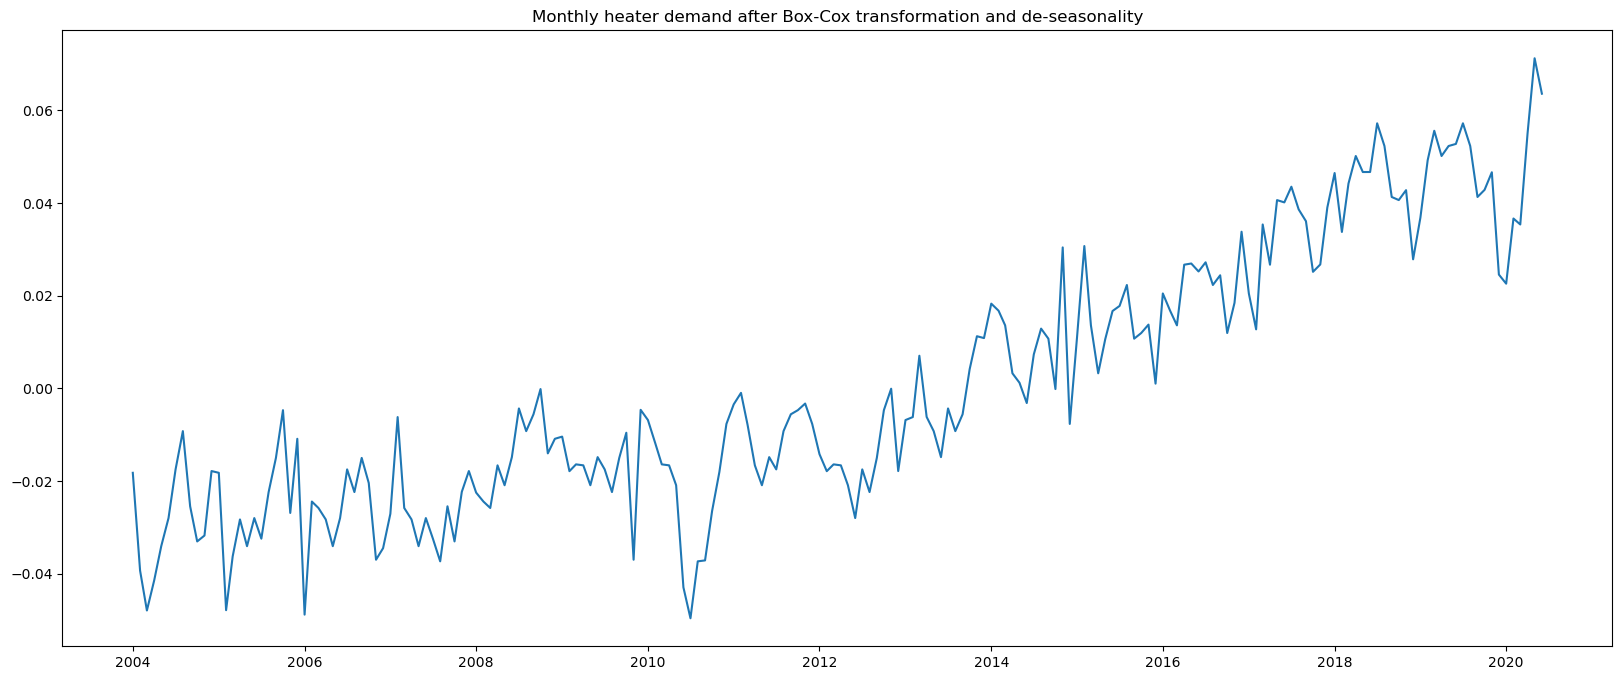

In [13]:
heater['demand_de_season'] = heater['demand_BC'] - heater['demand_month_avg']
heater = heater.sort_values(by='year_month')
plt.figure(figsize = (20,8))
plt.plot(heater['year_month'], heater['demand_de_season'])
plt.title('Monthly heater demand after Box-Cox transformation and de-seasonality')
plt.show()

The seasonality is removed. The time series data has an increasing trend.

### 1.3.3 (c) Apply first-order differencing to de-trend the data

In [14]:
heater['demand_diff1'] = heater['demand_de_season'].diff()
heater.head()

,year_month,demand,demand_BC,month,demand_month_avg,demand_de_season,demand_diff1
0,2004-01-01,27,1.336452,1,1.354655,-0.018203,NaN
1,2004-02-01,18,1.284380,2,1.323694,-0.039314,-0.021111
2,2004-03-01,14,1.244309,3,1.292226,-0.047917,-0.008603
3,2004-04-01,13,1.231157,4,1.272577,-0.041419,0.006498
4,2004-05-01,13,1.231157,5,1.265195,-0.034038,0.007382


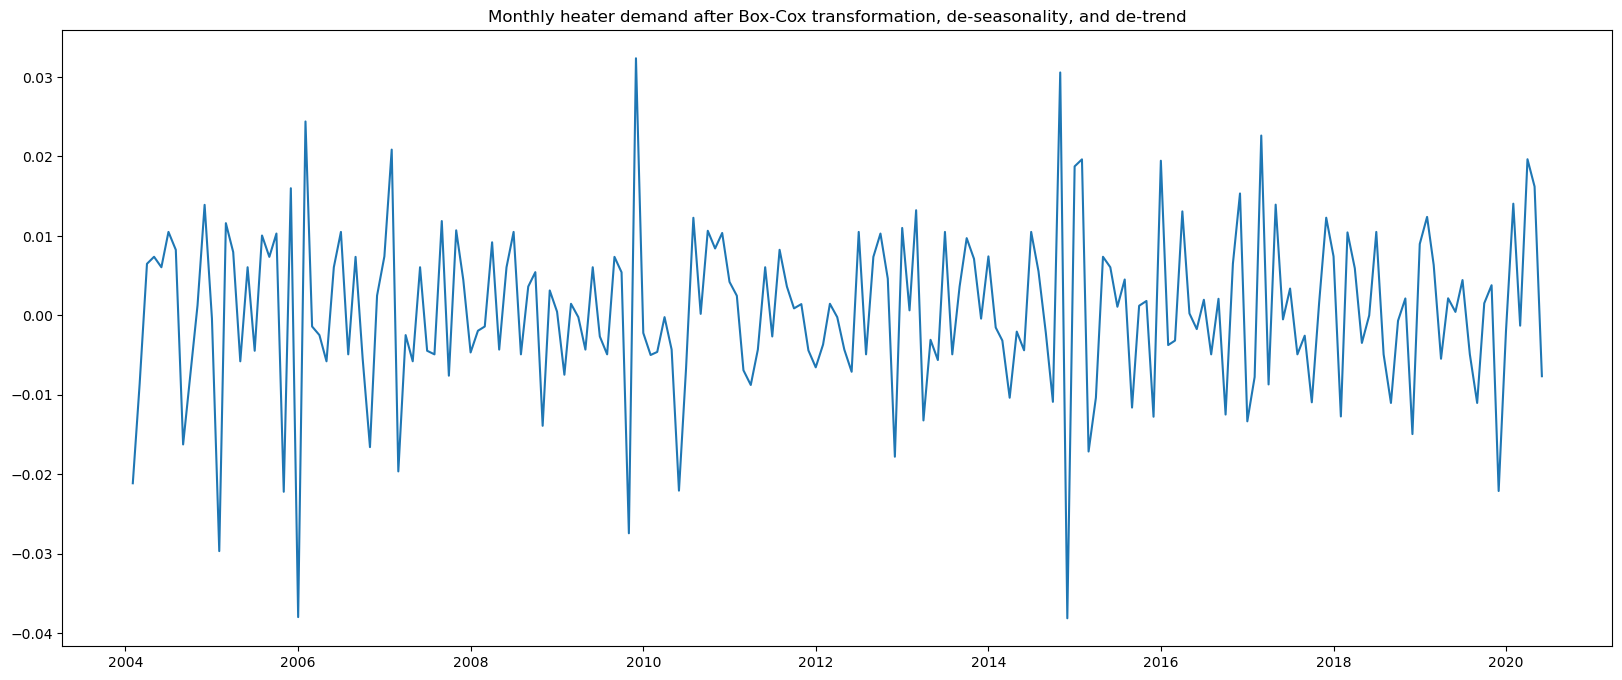

In [15]:
plt.figure(figsize = (20,8))
plt.plot(heater['year_month'], heater['demand_diff1'])
plt.title('Monthly heater demand after Box-Cox transformation, de-seasonality, and de-trend')
plt.show()

Looks much better. Let's confirm with the KPSS test.

In [16]:
_, pval, __, ___ = kpss(heater['demand_diff1'][1:], regression = 'c', nlags = 'auto') # do not include the first NaN value
print('p Value to the KPSS test is: ',pval)

p Value to the KPSS test is:  0.1


Because p-value is above 0.05, we consider the time series as stationary at a confidence level of 95%. Now, we are ready to apply an ARMA model.

## 1.4 Split into train and test (last 12 months as test)

In [17]:
train = heater[:-12]
test = heater[-12:]
train.shape, test.shape

((186, 7), (12, 7))

### Plot training and testing data

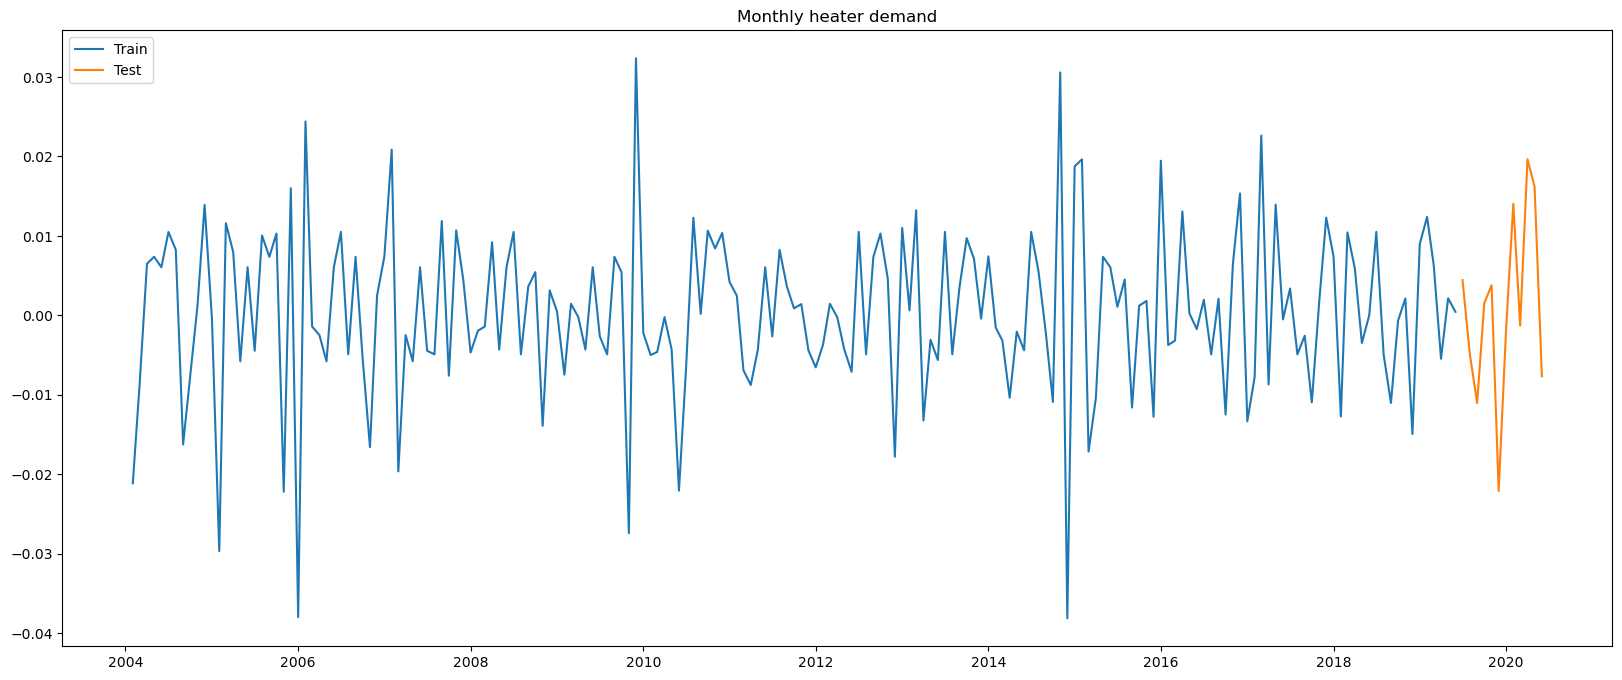

In [18]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['demand_diff1'], label = 'Train')
plt.plot(test['year_month'], test['demand_diff1'], label = 'Test')
plt.legend(loc = 'upper left')
plt.title('Monthly heater demand')
plt.show()

# 2: Choose, Train and Evaluate Models

Each model: choose orders → train and forecast → plot forecast vs actuals → RMSE.

## 2.1 Model 1: ARMA(2,1)

### 2.1.1 Choose ARMA orders with PACF and ACF

#### Use PACF plot to find out the order (i.e., p) of autoregression (AR).

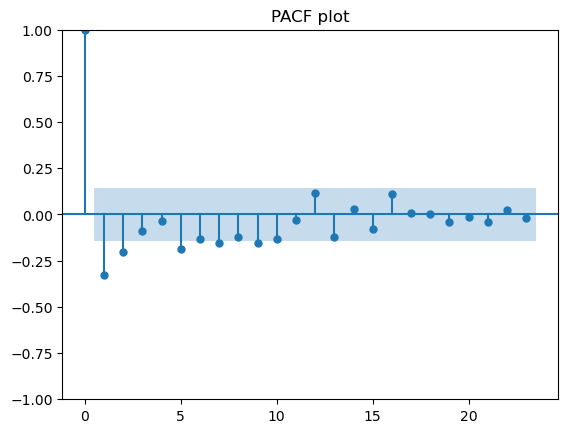

In [19]:
plot_pacf(train['demand_diff1'][1:], title = 'PACF plot');
plt.show()

Set p = 2. Simpler model is preferred.

#### Use ACF plot to find out the order (i.e., q) of moving average (MA).

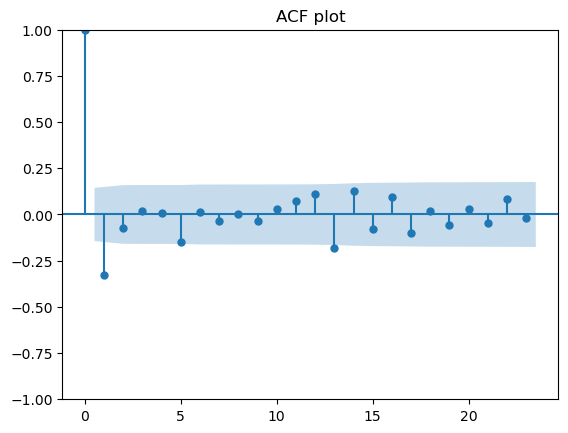

In [20]:
plot_acf(train['demand_diff1'][1:], title = 'ACF plot');
plt.show()

Set q = 1.

### 2.1.2 Train ARIMA(2,0,1) and forecast 12 months

In [21]:
# 2,0,1 ARIMA Model
model = ARIMA(train['demand_diff1'], order=(2,0,1))
model_fit = model.fit()
y_predict = model_fit.forecast(12)

### 2.1.3 Plot forecast vs actuals

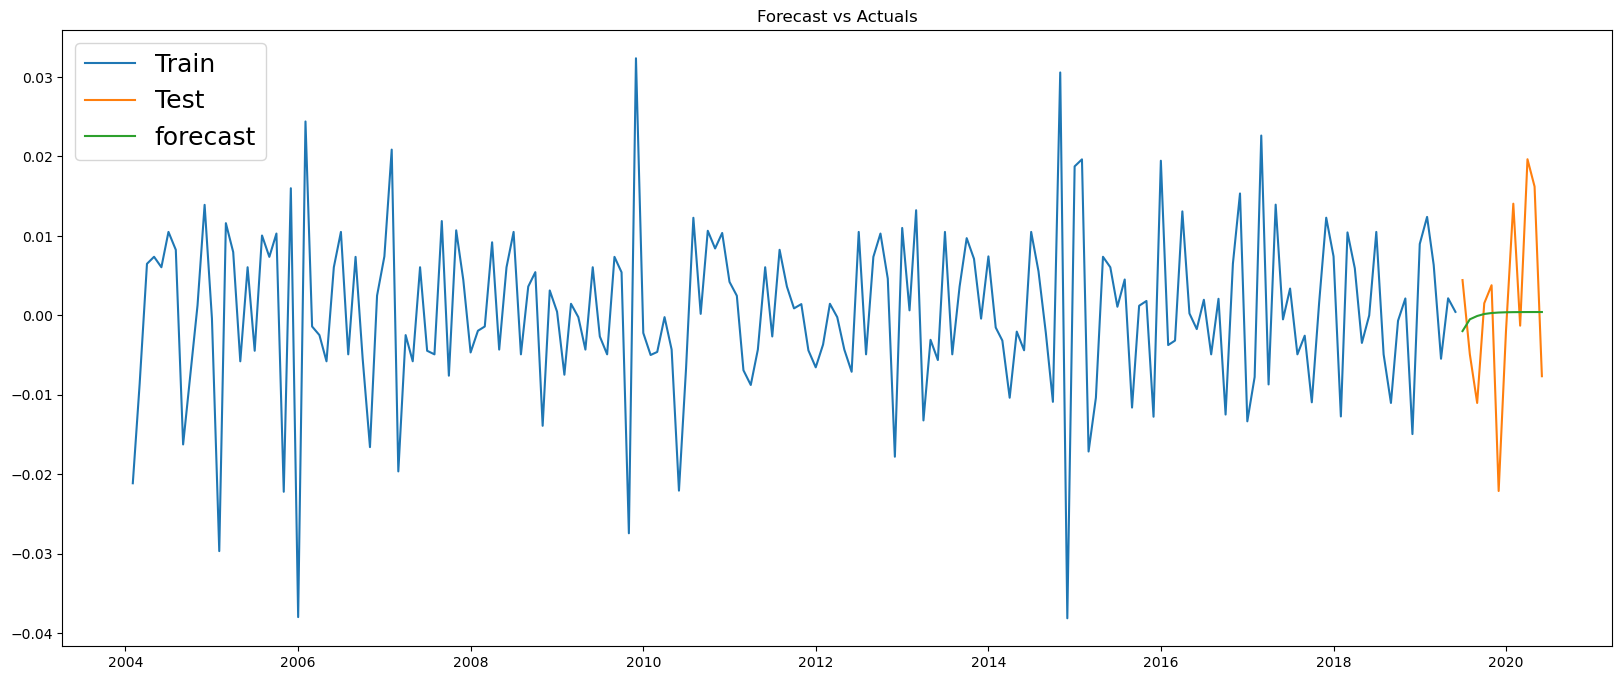

In [22]:
# Plot
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['demand_diff1'], label = 'Train')
plt.plot(test['year_month'], test['demand_diff1'], label = 'Test')
plt.plot(test['year_month'], y_predict, label='forecast')
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=18)
plt.show()

### 2.1.4 RMSE

In [23]:
rmse_arma = root_mean_squared_error(y_true=test['demand_diff1'], y_pred=y_predict)
print(rmse_arma)

0.011463835888619206


## 2.2 Model 2: ARIMA(2,1,1) on the de-seasonalised demand

### 2.2.1 Train ARIMA(2,1,1) and forecast 12 months

In [24]:
model = ARIMA(train['demand_de_season'], order=(2,1,1)) 
model_fit = model.fit()
y_predict = model_fit.forecast(12)

### 2.2.2 Plot forecast vs actuals

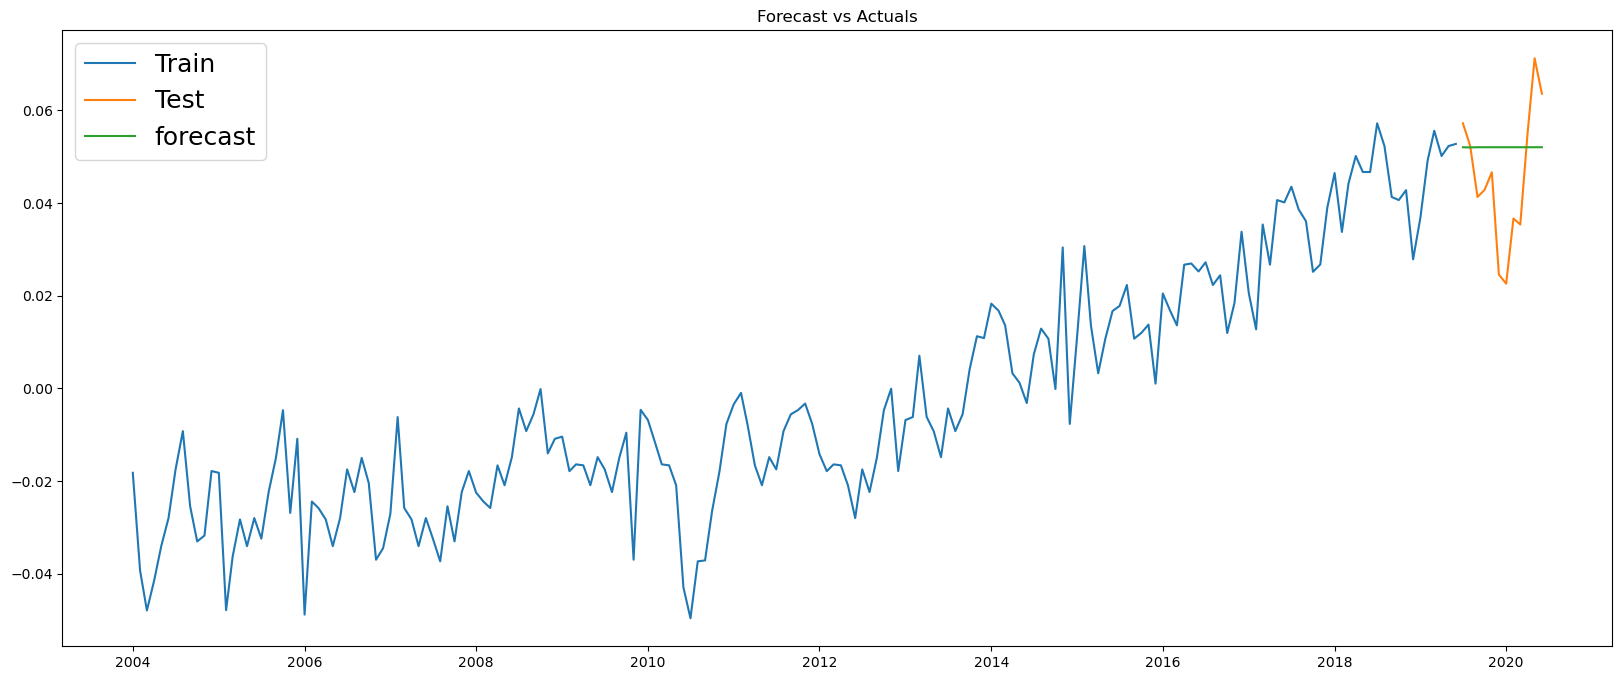

In [25]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['demand_de_season'], label = 'Train')
plt.plot(test['year_month'], test['demand_de_season'], label = 'Test')
plt.plot(test['year_month'], y_predict, label='forecast')
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=18)
plt.show()

### 2.2.3 RMSE

In [26]:
rmse_arima = root_mean_squared_error(y_true=test['demand_de_season'], y_pred=y_predict)
print(rmse_arima)

0.015556229626927931


## 2.3 Model 3: Seasonal ARIMA on the Box-Cox transformed demand

Let's try seasonal ARIMA on the Box-Cox transformed demand. The non-seasonal part is the same as before, i.e. p = 2, d = 1, q = 1.

Because the season is at the month level, we take a difference with lag = 12 to examine the seasonal AR (P), I (D) and MA (Q). For instance, demand in January this year minus demand in January last year.

### 2.3.1 Choose seasonal orders

#### Inspect the lag-12 differenced series

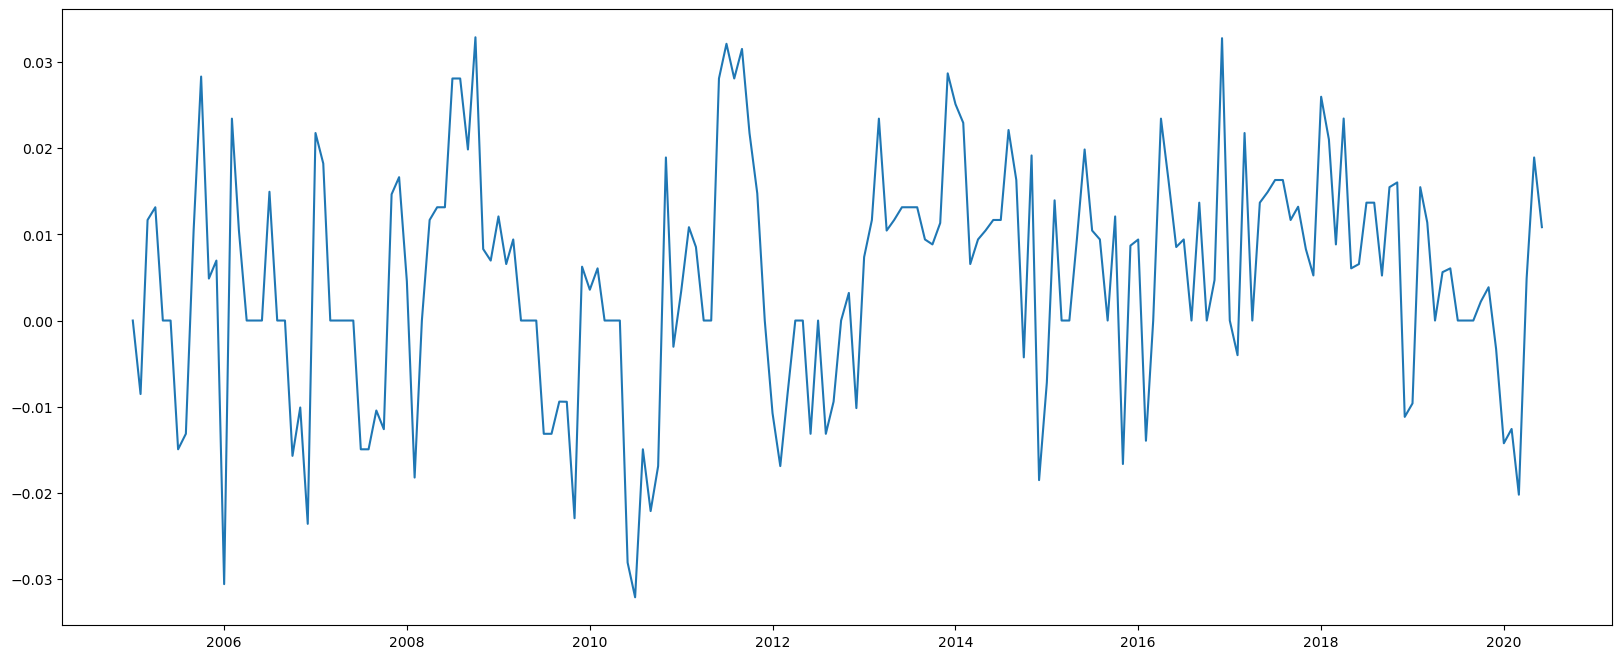

In [27]:
# plot the demand after differencing with lag = 12
plt.figure(figsize = (20,8))
plt.plot(heater['year_month'], heater['demand_BC'].diff(12))
plt.show()

The plot has no trend. So we do not take a further difference, i.e. D = 0.

#### Use PACF to find seasonal P. P = 1.

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5          NaN
6          NaN
7          NaN
8          NaN
9          NaN
10         NaN
11         NaN
12    0.000000
13   -0.008535
14    0.011675
15    0.013152
16    0.000000
17    0.000000
18   -0.014951
19   -0.013152
Name: demand_BC, dtype: float64


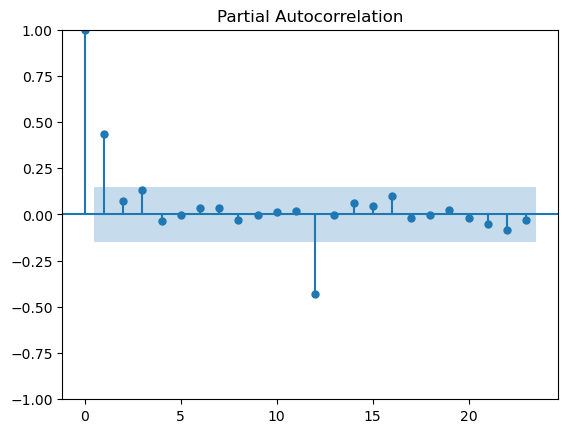

In [28]:
print(train['demand_BC'].diff(12).head(n=20))
plot_pacf(train['demand_BC'].diff(12)[12:]);
plt.show()

#### Use ACF to find seasonal Q. Q = 3.

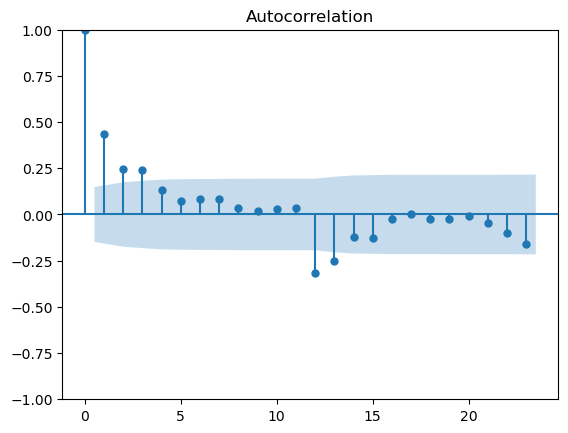

In [29]:
plot_acf(train['demand_BC'].diff(12)[12:]);
plt.show()

### 2.3.2 Train seasonal ARIMA and forecast 12 months

In [30]:
model = ARIMA(train['demand_BC'], order=(2,1,1), seasonal_order = (1,0,3,12))
model_fit = model.fit()
y_predict = model_fit.forecast(12)

### 2.3.3 Plot forecast vs actuals

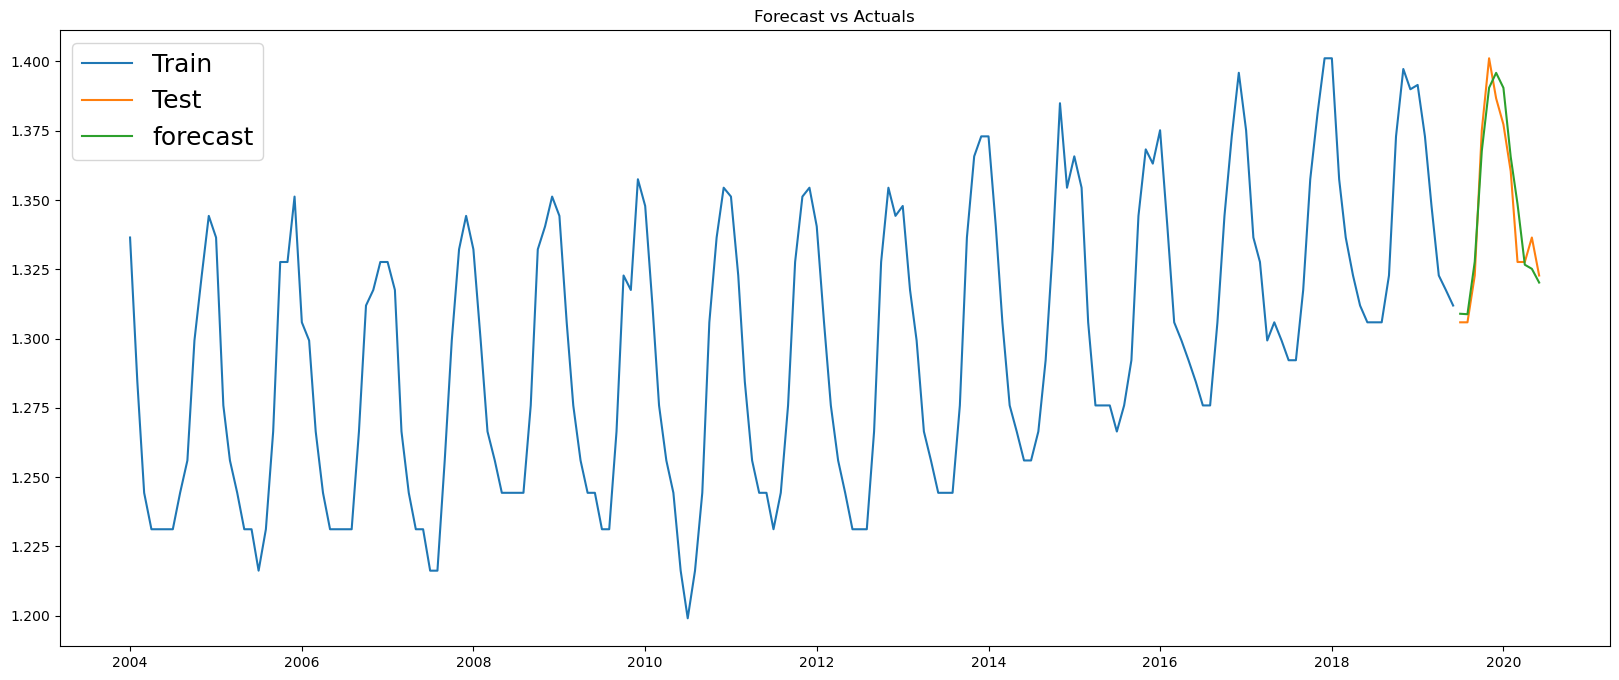

In [31]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['demand_BC'], label = 'Train')
plt.plot(test['year_month'], test['demand_BC'], label = 'Test')
plt.plot(test['year_month'], y_predict, label='forecast')
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=18)
plt.show()

### 2.3.4 RMSE

In [32]:
rmse_sarima = root_mean_squared_error(y_true=test['demand_BC'], y_pred=y_predict)
print(rmse_sarima)

0.009449094140482265


## 2.4 Model 4: ETS / Holt-Winters on the Box-Cox transformed demand

### 2.4.1 Train ETS (additive trend and seasonality) and forecast 12 months

In [33]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
hw = ETSModel(train['demand_BC'], trend='add', seasonal = 'add', seasonal_periods = 12)
hw_fit = hw.fit()
y_predict = hw_fit.forecast(12)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           16     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f= -2.20173D+00    |proj g|=  5.05989D+00

At iterate    1    f= -2.27563D+00    |proj g|=  1.85481D+01

At iterate    2    f= -2.76110D+00    |proj g|=  5.47768D+01

At iterate    3    f= -2.90159D+00    |proj g|=  3.24794D+01

At iterate    4    f= -2.94833D+00    |proj g|=  3.25411D+01

At iterate    5    f= -2.98491D+00    |proj g|=  6.62869D+00

At iterate    6    f= -3.01002D+00    |proj g|=  5.97869D+00

At iterate    7    f= -3.13362D+00    |proj g|=  4.75853D+00

At iterate    8    f= -3.14705D+00    |proj g|=  6.14173D-01

At iterate    9    f= -3.14801D+00    |proj g|=  3.61792D-01

At iterate   10    f= -3.15032D+00    |proj g|=  2.01613D-01

At iterate   11    f= -3.15825D+00    |proj g|=  7.68268D-01

At iterate   12    f= -3.16593D+00    |proj g|=  1.07471D+00

At iterate   13    f= -3.1

### 2.4.2 Plot forecast vs actuals

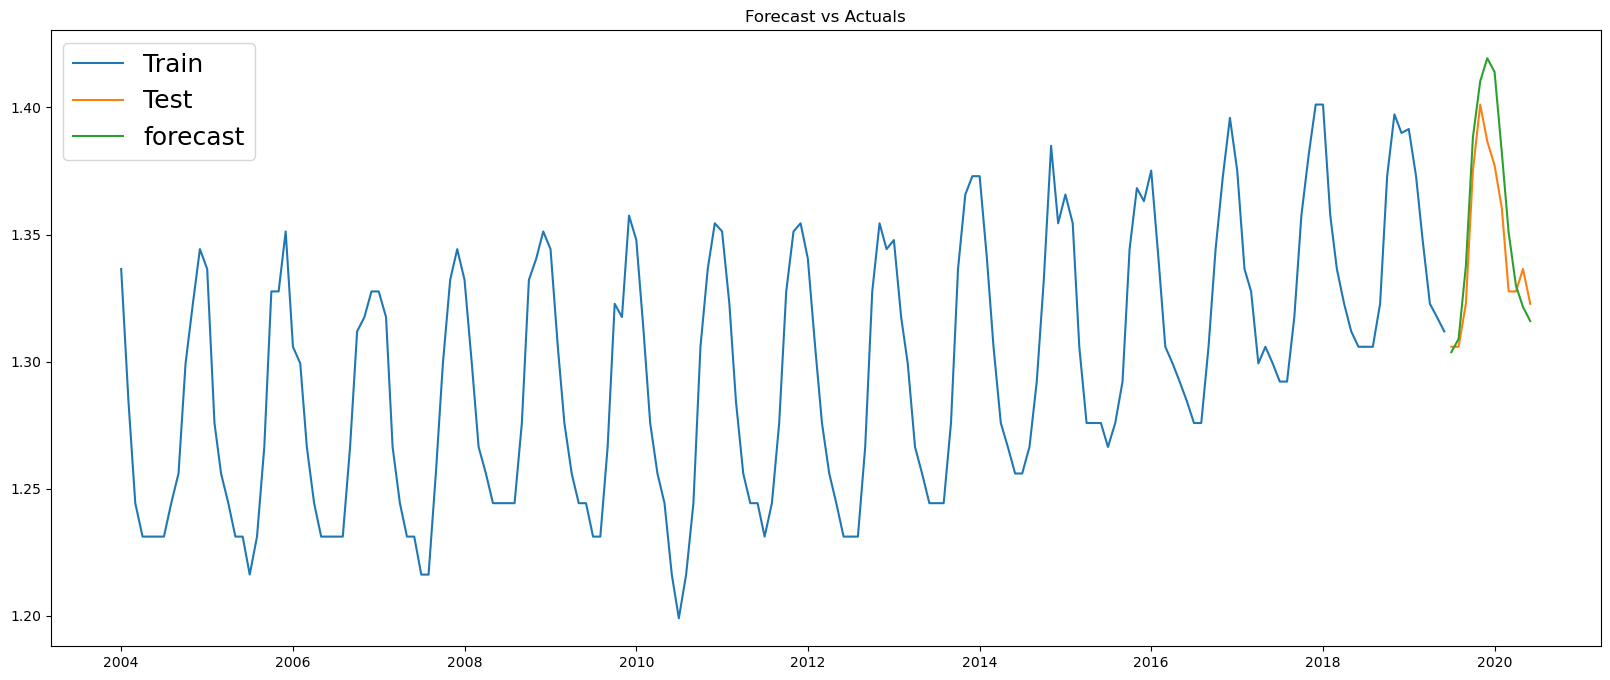

In [34]:
plt.figure(figsize = (20,8))
plt.plot(train['year_month'], train['demand_BC'], label = 'Train')
plt.plot(test['year_month'], test['demand_BC'], label = 'Test')
plt.plot(test['year_month'], y_predict, label='forecast')
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=18)
plt.show()

### 2.4.3 RMSE

In [35]:
rmse_hw = root_mean_squared_error(y_pred=y_predict, y_true=test['demand_BC'])
print(rmse_hw)

0.018704949355111137


## 2.5 Model comparison

| Model | Fitted on | RMSE |
|---|---|---|
| ARMA(2,1) | Box-Cox, de-seasonalised, differenced series | 0.0115 |
| ARIMA(2,1,1) | Box-Cox, de-seasonalised series | 0.0156 |
| Seasonal ARIMA | Box-Cox series | 0.0094 |
| ETS (Holt-Winters) | Box-Cox series | 0.0187 |


# Week 9 Assignment(Extra): Weather Time Series Forecasting

**Data:** `weather.csv`
**Task:** Choose a weather variable, forecast it using the ARIMA pipeline, and compare it with another forecasting model.

### Requirements:
1. **Data Prep:** Select a variable, resample it to monthly averages, and split the last 12 months as the test set.
2. **ARIMA:** Apply the Tutorial 9 pipeline (transformations, ACF/PACF, etc.) using train data only to fit and forecast.
3. **Alternative Model:** Choose a second model and forecast the same period.
4. **Evaluation:** Plot actual vs. predicted values for both models, calculate their RMSE, and write a brief conclusion on which model performed better and why.

**Submission:** One Jupyter Notebook with your code, plots, RMSE results, and conclusion.